In [ ]:
import numpy as np
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parents[1]
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from pulse_vqe_entanglement.dataclasses import SimulationConfig
from pulse_vqe_entanglement.sqe_gate import sqe_gate_optimisation
from pulse_vqe_entanglement.plotting_gate import plot_sqe_gate_optimisation

Tracing control amplitude graph.
Gate infidelity optimisation results:
GI=3.868e-02, nit=3, success=True, grad_norm=0.000e+00
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.


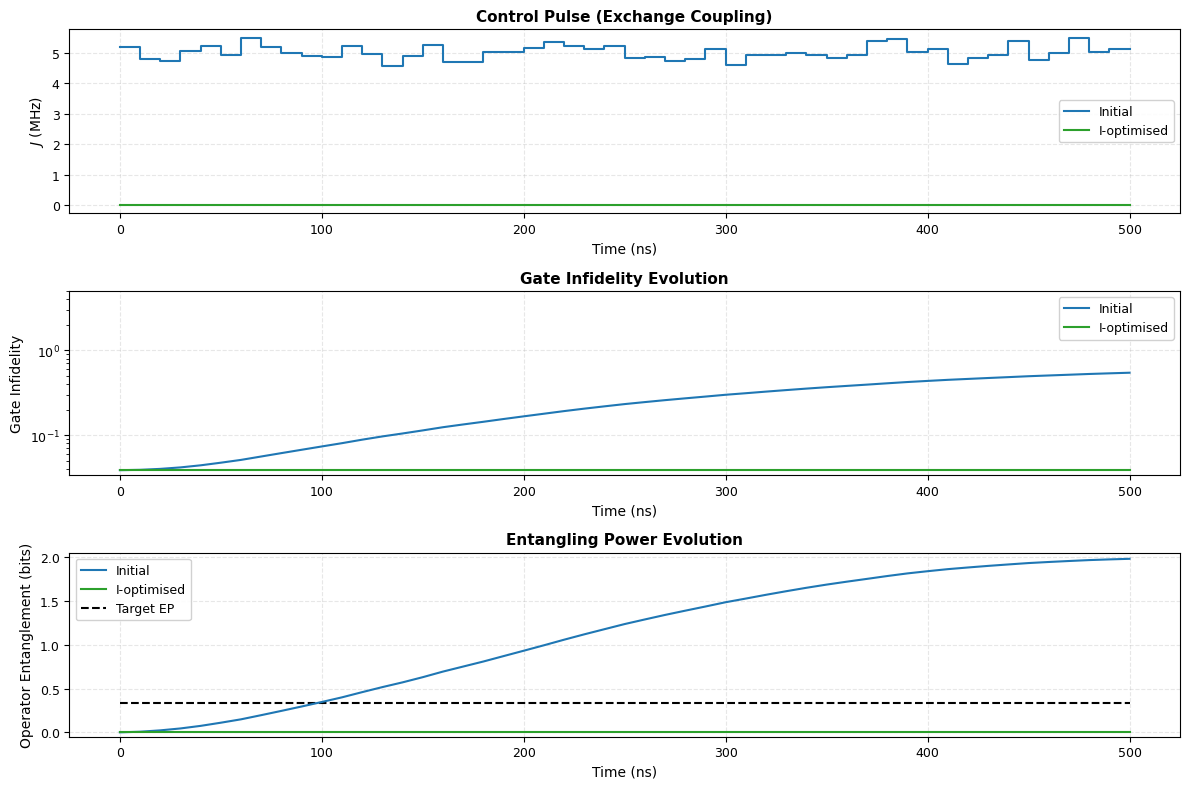

In [10]:
config = SimulationConfig(
    zeeman_splittings=np.array([0.0, 0.0]),
    theta_target=0.1 * np.pi,
    n_time_steps=50,
    n_discretisation=1,
    T=500.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=1e-1,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    optimisation_target="gate",
    run_mode="infidelity",
    init_seed=123,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e8,
    n_outer=30,
    inner_maxiter=500,
    fd_eps=1e-6,
)

results = sqe_gate_optimisation(config)
plot_sqe_gate_optimisation(results)

In [11]:
config = SimulationConfig(
    zeeman_splittings=np.array([0.0, 8.0]),
    initial_state=np.array([0.0, 0.0, 1.0, 0.0], dtype=np.complex128),
    theta_target=0.0 * np.pi,
    n_time_steps=2,
    n_discretisation=1,
    T=100.0,
    max_drive_strength=0.0,
    J_max=10.0,
    J_min=0.0,
    J_init_scale=0.0,
    feromagnetic=False,
    gtol=1e-12,
    maxiter=500,
    optimisation_target="gate",
    run_mode="infidelity",
    init_seed=123,

    # primal-dual settings
    S_max=0.01,
    eps_infidelity=1e-12,
    rho=0.0,
    dual_lr=1e8,
    n_outer=30,
    inner_maxiter=500,
    fd_eps=1e-6,
)

In [ ]:
from pulse_vqe_entanglement.sqe_gate import _make_system

sys = _make_system(config)

from pulse_vqe_entanglement.sqe_gate import _get_unitary_traj, get_gate_infidelity_traj

x = np.zeros(config.n_time_steps * config.n_J_channels, dtype=np.float64)
x = x-1.0

U_traj = _get_unitary_traj(config, sys, x)
print(U_traj.shape)
print(U_traj)

target_gate = np.eye(4, dtype=np.complex128)

inf_traj = get_gate_infidelity_traj(U_traj, target_gate)
print(inf_traj)

Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
Tracing control amplitude graph.
(3, 4, 4)
[[[ 1.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
    0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j]
  [ 0.00000000e+00+0.00000000e+00j  1.00000000e+00+0.00000000e+00j
    0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j]
  [ 0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
    1.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j]
  [ 0.00000000e+00+0.00000000e+00j  0.00000000e+00+0.00000000e+00j
    0.00000000e+00+0.00000000e+00j  1.00000000e+00+0.00000000e+00j]]

 [[ 9.80066577e-01+1.98669334e-01j -1.93735766e-16-4.71475451e-17j
   -1.38224614e-16+2.63308634e-17j  5.53263622e-19-1.42471219e-18j]
  [-1.93301049e-16-4.22545489e-17j  9.80066577e-01+1.98669334e-01j
   -3.13585455e-16+6.49897426e-17j -7.25213843e-17+2.58839190e-17j]
  [-1.69257375e-16-3.73806548e-17j -4.15083549